In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/hour.csv')

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


In [3]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


In [4]:
print('Missing values:')
display(df.isnull().sum())

print('Duplicate rows:', df.duplicated().sum())

Missing values:


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0


In [5]:
for column in df.columns:
    print(f'{column}: {df[column].nunique()} unique values')

instant: 17379 unique values
dteday: 731 unique values
season: 4 unique values
yr: 2 unique values
mnth: 12 unique values
hr: 24 unique values
holiday: 2 unique values
weekday: 7 unique values
workingday: 2 unique values
weathersit: 4 unique values
temp: 50 unique values
atemp: 65 unique values
hum: 89 unique values
windspeed: 30 unique values
casual: 322 unique values
registered: 776 unique values
cnt: 869 unique values


In [6]:
target = 'cnt'

drop_columns = ['instant', 'dteday', 'casual', 'registered']

y = df[target].copy()

X_original = df.drop(columns=drop_columns + [target]).copy()

X_engineered = X_original.copy()

print('Original features:', X_original.shape)
print('Engineered features:', X_engineered.shape)
print('Target:', y.shape)

display(X_original.head())

Original features: (17379, 12)
Engineered features: (17379, 12)
Target: (17379,)


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0


In [7]:
X_engineered['sin_hour'] = np.sin(2 * np.pi * X_engineered['hr'] / 24)
X_engineered['cos_hour'] = np.cos(2 * np.pi * X_engineered['hr'] / 24)

X_engineered['sin_month'] = np.sin(2 * np.pi * (X_engineered['mnth'] - 1) / 12)
X_engineered['cos_month'] = np.cos(2 * np.pi * (X_engineered['mnth'] - 1) / 12)

X_engineered = X_engineered.drop(columns=['hr', 'mnth'])

display(X_engineered[['sin_hour', 'cos_hour', 'sin_month', 'cos_month']].head(10))

,sin_hour,cos_hour,sin_month,cos_month
0,0.000000,1.000000e+00,0.0,1.0
1,0.258819,9.659258e-01,0.0,1.0
2,0.500000,8.660254e-01,0.0,1.0
3,0.707107,7.071068e-01,0.0,1.0
4,0.866025,5.000000e-01,0.0,1.0
5,0.965926,2.588190e-01,0.0,1.0
6,1.000000,6.123234e-17,0.0,1.0
7,0.965926,-2.588190e-01,0.0,1.0
8,0.866025,-5.000000e-01,0.0,1.0
9,0.707107,-7.071068e-01,0.0,1.0


In [8]:
X_engineered = pd.get_dummies(
    X_engineered,
    columns=['weekday', 'season', 'weathersit'],
    prefix=['weekday', 'season', 'weather'],
    dtype=int
)

display(X_engineered.head())
print('Number of features:', X_engineered.shape[1])

,yr,holiday,workingday,temp,atemp,hum,windspeed,sin_hour,cos_hour,sin_month,...,weekday_5,weekday_6,season_1,season_2,season_3,season_4,weather_1,weather_2,weather_3,weather_4
0,0,0,0,0.24,0.2879,0.81,0.0,0.000000,1.000000,0.0,...,0,1,1,0,0,0,1,0,0,0
1,0,0,0,0.22,0.2727,0.80,0.0,0.258819,0.965926,0.0,...,0,1,1,0,0,0,1,0,0,0
2,0,0,0,0.22,0.2727,0.80,0.0,0.500000,0.866025,0.0,...,0,1,1,0,0,0,1,0,0,0
3,0,0,0,0.24,0.2879,0.75,0.0,0.707107,0.707107,0.0,...,0,1,1,0,0,0,1,0,0,0
4,0,0,0,0.24,0.2879,0.75,0.0,0.866025,0.500000,0.0,...,0,1,1,0,0,0,1,0,0,0


Number of features: 26


In [9]:
X_engineered['rush_hour'] = (
    (df['workingday'] == 1) &
    (
        df['hr'].between(7, 9) |
        df['hr'].between(16, 19)
    )
).astype(int)

X_engineered['temp_hum'] = X_engineered['temp'] * X_engineered['hum']

print('Rush hour distribution:')
display(X_engineered['rush_hour'].value_counts())

print('New features:')
display(X_engineered[['rush_hour', 'temp_hum']].head(10))

print('Total features:', X_engineered.shape[1])

Rush hour distribution:


rush_hour
0    13897
1     3482
Name: count, dtype: int64

New features:


,rush_hour,temp_hum
0,0,0.1944
1,0,0.1760
2,0,0.1760
3,0,0.1800
4,0,0.1800
5,0,0.1800
6,0,0.1760
7,0,0.1720
8,0,0.1800
9,0,0.2432


Total features: 28


In [10]:
print('Original dataset:', X_original.shape)
print('Engineered dataset:', X_engineered.shape)
print('Target:', y.shape)

print('\nMissing values:', X_engineered.isnull().sum().sum())
print('Duplicate rows:', X_engineered.duplicated().sum())
print('Infinite values:', np.isinf(X_engineered.select_dtypes(include=np.number)).sum().sum())

print('\nFeature columns:')
print(X_engineered.columns.tolist())

Original dataset: (17379, 12)
Engineered dataset: (17379, 28)
Target: (17379,)

Missing values: 0
Duplicate rows: 10
Infinite values: 0

Feature columns:
['yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'sin_hour', 'cos_hour', 'sin_month', 'cos_month', 'weekday_0', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6', 'season_1', 'season_2', 'season_3', 'season_4', 'weather_1', 'weather_2', 'weather_3', 'weather_4', 'rush_hour', 'temp_hum']


In [11]:
duplicate_mask = X_engineered.duplicated(keep=False)

print('Number of duplicated rows:', duplicate_mask.sum())

display(
    pd.concat(
        [
            X_engineered[duplicate_mask],
            y[duplicate_mask].rename('cnt')
        ],
        axis=1
    ).sort_values(by=X_engineered.columns.tolist())
)

Number of duplicated rows: 20


,yr,holiday,workingday,temp,atemp,hum,windspeed,sin_hour,cos_hour,sin_month,...,season_2,season_3,season_4,weather_1,weather_2,weather_3,weather_4,rush_hour,temp_hum,cnt
7958,0,0,0,0.24,0.2576,0.65,0.1045,1.000000,6.123234e-17,-5.000000e-01,...,0,0,1,1,0,0,0,0,0.1560,11
8126,0,0,0,0.24,0.2576,0.65,0.1045,1.000000,6.123234e-17,-5.000000e-01,...,0,0,1,1,0,0,0,0,0.1560,11
3643,0,0,0,0.74,0.6667,0.51,0.0000,-0.965926,-2.588190e-01,5.000000e-01,...,1,0,0,1,0,0,0,0,0.3774,390
3979,0,0,0,0.74,0.6667,0.51,0.0000,-0.965926,-2.588190e-01,5.000000e-01,...,1,0,0,1,0,0,0,0,0.3774,397
7931,0,0,1,0.22,0.2727,0.80,0.0000,0.707107,7.071068e-01,-5.000000e-01,...,0,0,1,1,0,0,0,0,0.1760,1
8099,0,0,1,0.22,0.2727,0.80,0.0000,0.707107,7.071068e-01,-5.000000e-01,...,0,0,1,1,0,0,0,0,0.1760,6
7932,0,0,1,0.22,0.2727,0.80,0.0000,0.866025,5.000000e-01,-5.000000e-01,...,0,0,1,1,0,0,0,0,0.1760,3
8100,0,0,1,0.22,0.2727,0.80,0.0000,0.866025,5.000000e-01,-5.000000e-01,...,0,0,1,1,0,0,0,0,0.1760,2
11804,1,0,0,0.50,0.4848,0.48,0.0000,0.258819,9.659258e-01,8.660254e-01,...,1,0,0,1,0,0,0,0,0.2400,93
11972,1,0,0,0.50,0.4848,0.48,0.0000,0.258819,9.659258e-01,8.660254e-01,...,1,0,0,1,0,0,0,0,0.2400,104


In [12]:
print('Original dates:')
display(df.loc[[3643, 3979, 7931, 8099, 11907, 12075], 
               ['dteday', 'hr', 'mnth', 'weekday', 'cnt']])

Original dates:


,dteday,hr,mnth,weekday,cnt
3643,2011-06-05,17,6,0,390
3979,2011-06-19,17,6,0,397
7931,2011-12-02,3,12,5,1
8099,2011-12-09,3,12,5,6
11907,2012-05-16,8,5,3,650
12075,2012-05-23,8,5,3,719


In [13]:
original_data = X_original.copy()
original_data['cnt'] = y

engineered_data = X_engineered.copy()
engineered_data['cnt'] = y

original_data.to_csv(
    '../data/processed/bike_sharing_original.csv',
    index=False
)

engineered_data.to_csv(
    '../data/processed/bike_sharing_engineered.csv',
    index=False
)

print('Files saved successfully!')
print('Original dataset:', original_data.shape)
print('Engineered dataset:', engineered_data.shape)

Files saved successfully!
Original dataset: (17379, 13)
Engineered dataset: (17379, 29)


## Feature Engineering Summary

The original dataset contains 17,379 observations and 12 input features.

The engineered dataset contains 17,379 observations and 28 input features.

The following transformations were performed:
- Cyclical encoding of hour and month.
- One-hot encoding of weekday, season, and weather situation.
- Creation of a working-day rush-hour indicator.
- Creation of a temperature-humidity interaction feature.
- Removal of identifiers and target leakage columns.

No missing or infinite values were found.

Both datasets were saved in the data/processed folder for further model training and comparison.

In [14]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(y))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

X_original_train = X_original.iloc[train_indices].copy()
X_original_test = X_original.iloc[test_indices].copy()

X_engineered_train = X_engineered.iloc[train_indices].copy()
X_engineered_test = X_engineered.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

print('Training samples:', len(y_train))
print('Testing samples:', len(y_test))

Training samples: 13903
Testing samples: 3476


In [15]:
datasets = {
    'X_original_train': X_original_train,
    'X_original_test': X_original_test,
    'X_engineered_train': X_engineered_train,
    'X_engineered_test': X_engineered_test,
    'y_train': y_train,
    'y_test': y_test
}

for name, data in datasets.items():
    data.to_csv(f'../data/processed/{name}.csv', index=False)

print('All train/test files saved successfully!')

All train/test files saved successfully!


In [16]:
print('Original features:')
print('Train:', X_original_train.shape)
print('Test:', X_original_test.shape)

print('\nEngineered features:')
print('Train:', X_engineered_train.shape)
print('Test:', X_engineered_test.shape)

print('\nTarget:')
print('Train:', y_train.shape)
print('Test:', y_test.shape)

print('\nMissing values:')
print('Original:', X_original_train.isnull().sum().sum())
print('Engineered:', X_engineered_train.isnull().sum().sum())

print('\nTarget alignment:')
print('Original train:', X_original_train.index.equals(y_train.index))
print('Engineered train:', X_engineered_train.index.equals(y_train.index))
print('Original test:', X_original_test.index.equals(y_test.index))
print('Engineered test:', X_engineered_test.index.equals(y_test.index))

Original features:
Train: (13903, 12)
Test: (3476, 12)

Engineered features:
Train: (13903, 28)
Test: (3476, 28)

Target:
Train: (13903,)
Test: (3476,)

Missing values:
Original: 0
Engineered: 0

Target alignment:
Original train: True
Engineered train: True
Original test: True
Engineered test: True


In [17]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_engineered_train, y_train)

print('Random Forest training completed!')
print('Train R2:', rf_model.score(X_engineered_train, y_train))
print('Test R2:', rf_model.score(X_engineered_test, y_test))

Random Forest training completed!
Train R2: 0.9925363018219863
Test R2: 0.9463962789408231


In [18]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    rf_model,
    X_engineered_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='r2',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': X_engineered.columns,
    'importance_mean': permutation_result.importances_mean,
    'importance_std': permutation_result.importances_std
})

importance_df = importance_df.sort_values(
    by='importance_mean',
    ascending=False
).reset_index(drop=True)

display(importance_df)

,feature,importance_mean,importance_std
0,rush_hour,0.482693,0.013870
1,sin_hour,0.442609,0.009086
2,cos_hour,0.301274,0.013444
3,yr,0.196739,0.003844
4,workingday,0.143544,0.003642
5,temp,0.123419,0.004323
6,hum,0.032946,0.002554
7,atemp,0.028734,0.001814
8,season_1,0.021938,0.002165
9,weather_3,0.017675,0.002376


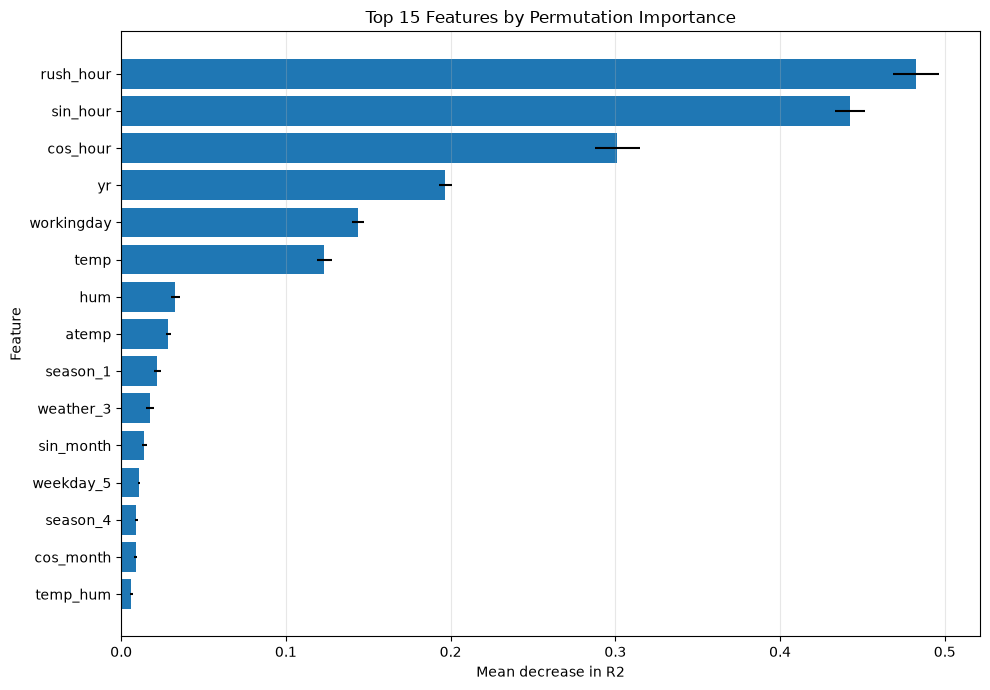

In [19]:
plt.figure(figsize=(10, 7))

top_features = importance_df.head(15).sort_values(
    by='importance_mean'
)

plt.barh(
    top_features['feature'],
    top_features['importance_mean'],
    xerr=top_features['importance_std']
)

plt.xlabel('Mean decrease in R2')
plt.ylabel('Feature')
plt.title('Top 15 Features by Permutation Importance')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

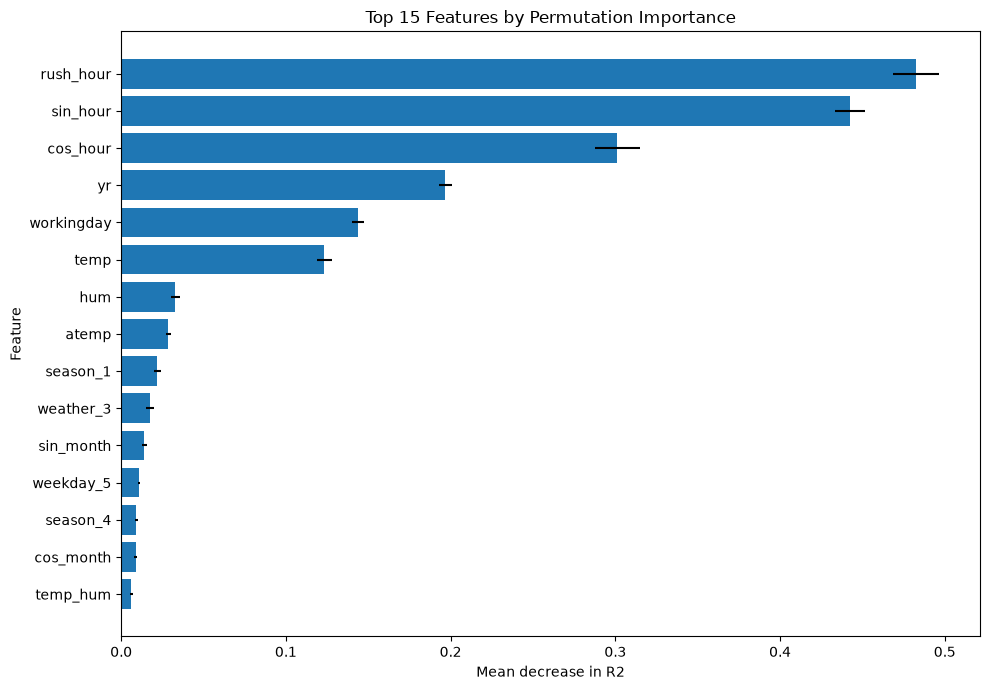

Feature importance results saved!


In [20]:
importance_df.to_csv(
    '../reports/feature_importance.csv',
    index=False
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['feature'],
    top_features['importance_mean'],
    xerr=top_features['importance_std']
)
plt.xlabel('Mean decrease in R2')
plt.ylabel('Feature')
plt.title('Top 15 Features by Permutation Importance')
plt.tight_layout()
plt.savefig(
    '../reports/figures/feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print('Feature importance results saved!')

In [21]:
original_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

original_rf.fit(X_original_train, y_train)

print('Original Random Forest training completed!')

Original Random Forest training completed!


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

original_predictions = original_rf.predict(X_original_test)
engineered_predictions = rf_model.predict(X_engineered_test)

comparison = pd.DataFrame({
    'Dataset': ['Original', 'Engineered'],
    'MAE': [
        mean_absolute_error(y_test, original_predictions),
        mean_absolute_error(y_test, engineered_predictions)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, original_predictions)),
        np.sqrt(mean_squared_error(y_test, engineered_predictions))
    ],
    'R2': [
        r2_score(y_test, original_predictions),
        r2_score(y_test, engineered_predictions)
    ]
})

display(comparison.round(4))

,Dataset,MAE,RMSE,R2
0,Original,24.9029,42.0694,0.9441
1,Engineered,24.4512,41.1993,0.9464


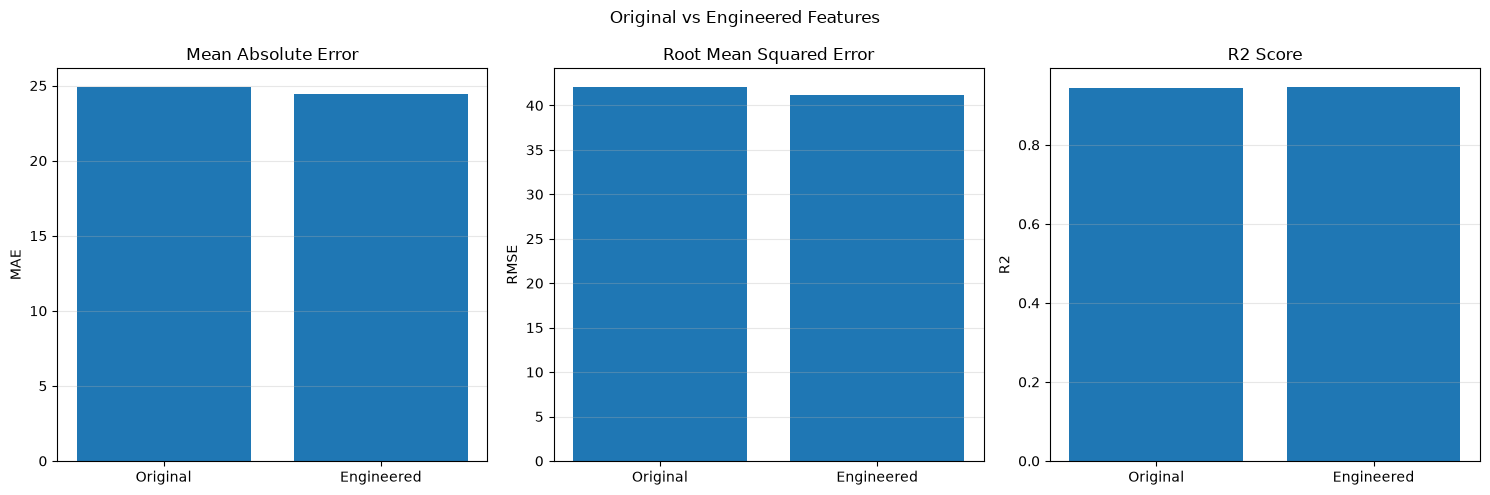

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ['MAE', 'RMSE', 'R2']
titles = ['Mean Absolute Error', 'Root Mean Squared Error', 'R2 Score']

for ax, metric, title in zip(axes, metrics, titles):
    ax.bar(comparison['Dataset'], comparison[metric])
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Original vs Engineered Features')
plt.tight_layout()
plt.show()

In [24]:
comparison.to_csv(
    '../reports/original_vs_engineered.csv',
    index=False
)

print('Comparison results saved!')

Comparison results saved!


In [25]:
feature_engineering_summary = pd.DataFrame({
    'Metric': ['Number of features', 'MAE', 'RMSE', 'R2'],
    'Original': [
        X_original.shape[1],
        comparison.loc[0, 'MAE'],
        comparison.loc[0, 'RMSE'],
        comparison.loc[0, 'R2']
    ],
    'Engineered': [
        X_engineered.shape[1],
        comparison.loc[1, 'MAE'],
        comparison.loc[1, 'RMSE'],
        comparison.loc[1, 'R2']
    ]
})

display(feature_engineering_summary.round(4))

feature_engineering_summary.to_csv(
    '../reports/feature_engineering_summary.csv',
    index=False
)

print('Final summary saved!')

,Metric,Original,Engineered
0,Number of features,12.0000,28.0000
1,MAE,24.9029,24.4512
2,RMSE,42.0694,41.1993
3,R2,0.9441,0.9464


Final summary saved!
